# Which genes respond when an enhancer is perturbed?

In the [Gasperini K562 screen](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE120861), a cell can carry several CRISPRi guides. Here we ask whether targeting a DNA element changes expression of a nearby gene. We’ll follow one candidate enhancer, `chr11.1735_top_two`, from its two guide assignments to its estimated effect on **LMO2**.

This subset contains 8,000 cells, 94 candidate enhancers, two transcription start site (TSS) controls, four non-targeting elements and 256 measured genes. Run the cells in order from `docs/tutorials/`. The files come with the checkout. The fit took about two minutes on an Apple Silicon laptop.

## 1. Open the screen and find the two measurements

A **MuData** object puts several measurements from the same experiment in one file (`.h5mu`). Each measurement is called a *modality*. Here `gene` contains RNA counts and `guide` records guide assignments. Displaying the object gives you an inventory of the modalities and their annotations.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import mudata
import numpy as np
import pandas as pd

source = Path("inputs/gasperini.h5mu")
run = Path("runs/gasperini")
run.mkdir(parents=True, exist_ok=True)
fitted = run / "fitted.h5mu"
with mudata.set_options(pull_on_update=False):
    screen = mudata.read_h5mu(source)
screen

MuData object with n_obs × n_vars = 8000 × 456
  2 modalities
    gene:	8000 × 256
      obs:	'total_umis', 'percent_mito', 'prep_batch', 'guide_count'
      var:	'gene_start', 'gene_end', 'gene_chr', 'symbol', 'gene_strand'
    guide:	8000 × 200
      obs:	'total_umis', 'percent_mito', 'prep_batch', 'guide_count'
      var:	'intended_target_name', 'intended_target_start', 'intended_target_end', 'intended_target_chr', 'guide_group', 'is_non_targeting'
      uns:	'intended_targets'
      varm:	'guide_intended_target_pairs'

Within a modality, rows are cells (`.obs_names`), columns are the measured features (`.var_names`), and `.X` holds the measurements. These are the locations we’ll use:

| Where to look | What you’ll find here |
| --- | --- |
| `rna.X` | RNA molecule counts for each cell and gene. |
| `rna.obs` | One row per cell, including whole-library RNA counts (`total_umis`), mitochondrial RNA fraction, preparation batch and the original guide count. |
| `rna.var` | One row per gene. Its index is the Ensembl ID used in the results. The `symbol` column gives the familiar name, such as LMO2. |
| `guides.X` | Cell-by-guide assignments. A positive entry means the cell carries that guide. |
| `guides.var` | The guide identities and annotations, including whether a guide is non-targeting. |
| `guides.varm["guide_intended_target_pairs"]` | The guide-by-element map. Its columns are named in `guides.uns["intended_targets"]`. Two different guides can point to the same element. |

Let’s look at the first three cells. The RNA totals and original guide counts describe the **full** screen, even though we kept only a subset of its genes and guides.

In [2]:
rna, guides = screen.mod["gene"], screen.mod["guide"]
assert rna.obs_names.equals(guides.obs_names)
rna.obs[["total_umis", "percent_mito", "prep_batch", "guide_count"]].head(3)

,total_umis,percent_mito,prep_batch,guide_count
cell,,,,
AAACCTGGTCTTCAAG-1_1A_1_SI-GA-E2,20490.0,0.047731,prep_batch_1,20.0
AAACGGGAGCCATCGC-1_1A_1_SI-GA-E2,31775.0,0.079843,prep_batch_1,30.0
AAACGGGTCACCACCT-1_1A_1_SI-GA-E2,22630.0,0.063588,prep_batch_1,45.0


## 2. Find the cells carrying guides for one enhancer

The unit we want to describe is the enhancer. A cell carrying either guide for that enhancer counts once toward its coverage, even if it carries both. We can read the guide map and count those cells directly.

In [3]:
mapping = guides.varm["guide_intended_target_pairs"]
elements = pd.Index(guides.uns["intended_targets"])
carriers = ((guides.X > 0) @ mapping) > 0
coverage = pd.Series(np.asarray(carriers.sum(axis=0)).ravel(), index=elements, name="cells")
print(f"{rna.n_obs:,} cells, {len(elements)} elements, {rna.n_vars} genes")
print(f"Median guides per cell in the original screen: {rna.obs.guide_count.median():g}")

example_element = "chr11.1735_top_two"
example_guides = guides.var.loc[guides.var.intended_target_name.eq(example_element)]
print(f"{coverage[example_element]} cells carry a guide for {example_element}")
example_guides[["intended_target_name", "is_non_targeting"]]

8,000 cells, 100 elements, 256 genes
Median guides per cell in the original screen: 29
54 cells carry a guide for chr11.1735_top_two


,intended_target_name,is_non_targeting
guide,,
GAAATGTTCTACCAGCTACA,chr11.1735_top_two,False
GCTGTGGCTCAGCCTCCCCA,chr11.1735_top_two,False


## 3. Specify which nearby genes to test

A *cis* candidate is an element paired with a nearby gene. We start with the screen’s candidate list and keep the pairs for which this teaching file contains both the element and the gene. Defining the list before looking at the results lets us ask a specific question: which nearby genes respond? PerTurbo still reports results for the other measured genes.

The candidate list uses Ensembl IDs. Here is the row that pairs our example enhancer with LMO2.

In [4]:
full_map = pd.read_parquet("../../examples/manuscript/gasperini-cis-candidates.parquet")
cis = full_map.loc[full_map.element.isin(elements) & full_map.gene.isin(rna.var_names)]
cis_path = run / "cis_candidates.parquet"
if cis_path.exists():
    if not pd.read_parquet(cis_path).equals(cis.reset_index(drop=True)):
        raise ValueError("Existing fit directory has a different cis family. Choose a fresh run directory.")
else:
    cis.to_parquet(cis_path, index=False)
print(f"{len(cis)} cis candidates across {cis.element.nunique()} enhancers")
lmo2 = rna.var_names[rna.var.symbol.eq("LMO2")].item()
cis.loc[cis.element.eq(example_element) & cis.gene.eq(lmo2)]

387 cis candidates across 94 enhancers


,element,gene
14288,chr11.1735_top_two,ENSG00000135363


## 4. Run PerTurbo

First PerTurbo learns how much RNA to expect for each gene across these cells, accounting for sequencing depth, mitochondrial RNA fraction and preparation batch. Then it estimates how expression changes with each element and how strongly each of its two guides contributes.

For the p-value, PerTurbo asks whether the association is stronger than expected by chance. Because cells can carry many guides, the chance comparison accounts for differences in how likely cells are to carry the guide. In the command, `--crt-pool all-cells` and `--crt-mechanism propensity` select that comparison; `--guide-effect-strategy relative` selects the two-guide effect model.

Run the next cell as written. It saves the input measurements and fitted results together in `runs/gasperini/fitted.h5mu`. The full command output goes into `runs/gasperini/cli.log`. Running the cell again reuses a completed fit with the same input and settings.

In [5]:
flags = f"""
--modality-key gene --perturbation-modality-key guide
--perturbation-element-varm-key guide_intended_target_pairs --perturbation-element-names-uns-key intended_targets
--library-size-key total_umis --continuous-covariates total_umis percent_mito --batch-covariate prep_batch
--guide-effect-strategy relative --crt-pool all-cells --cis-pairs {shlex.quote(str(run / "cis_candidates.parquet"))}
--size-factor-mode observed --likelihood negbin --prior normal
--num-steps-control 500 --num-steps-betas 500 --minibatch-size-control 512 --minibatch-size-betas 512
--step-size 0.01 --max-control-cells 8000 --crt --crt-mechanism propensity
--crt-tail-families saddlepoint --crt-saddlepoint-only --crt-two-sided equal-tail --crt-polish-baseline
--crt-gene-chunk-size 32 --crt-max-gather-gib 1 --crt-seed 0 --save-model-params --device cpu --no-progress-bar
"""
args = ["--input", str(source), "--out-dir", str(run), *shlex.split(flags)]
receipt = run / "teaching_command.json"
with source.open("rb") as handle:
    input_hash = hashlib.file_digest(handle, "sha256").hexdigest()
settings = {"args": args, "input_sha256": input_hash}
if fitted.exists():
    if not receipt.exists() or json.loads(receipt.read_text()) != settings:
        raise ValueError("Existing fit uses different settings. Choose a fresh run directory.")
    print(f"Using {fitted}")
else:
    # Keep the complete CLI transcript alongside the result.
    with (run / "cli.log").open("w") as log:
        result = subprocess.run([sys.executable, "-m", "perturbo.cli", *args], stdout=log, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError((run / "cli.log").read_text()[-4000:])
    receipt.write_text(json.dumps(settings, indent=2))
    print(f"Saved {fitted}")

Using runs/gasperini/fitted.h5mu


## 5. Read an enhancer–gene result

Open the fitted file with the same MuData reader. The RNA and guide data are still in `.mod`. PerTurbo stores its results under `.uns["_perturbo"]`. Here are the parts you’ll use most:

| Key inside `_perturbo` | What it holds |
| --- | --- |
| `effects` | One row per element and response gene, with the estimated expression change and its p- and q-values. |
| `efficiency` | One row per guide and response gene, with the estimated guide multiplier and its uncertainty. |
| `control_fit`, `size_factors`, `cell_covariates` | The fitted baseline and cell information reused in the companion simulation. |
| `metadata`, `crt_metadata` | Settings recorded for the fit and the significance tests. |

In `effects`, `posterior_mean` is the estimated natural-log fold change (lnFC) for the element. Zero means unchanged expression, negative means lower, and positive means higher. Exponentiating converts lnFC into a ratio: 0.5 on the ratio scale means half as much expression.

The p-value describes one test. For a list of discoveries, use the **q-value** for the set of tests you planned: `q_cis` for the candidate list, `q_element` for all genes tested for one element, or `q_global` for the whole tested screen. Here we call a cis pair at `q_cis < 0.1`, targeting a 10% false discovery rate across the reported list. A missing `q_cis` means the pair has no adjusted result in that family.

In [6]:
with mudata.set_options(pull_on_update=False):
    result = mudata.read_h5mu(fitted)
pt = result.uns["_perturbo"]
effects = pt["effects"]
example = effects.loc[effects.element.eq(example_element) & effects.gene.eq(lmo2)].copy()
example["expression_ratio"] = np.exp(example.posterior_mean)
example[["element", "gene", "posterior_mean", "expression_ratio", "p_value", "q_cis"]]

,element,gene,posterior_mean,expression_ratio,p_value,q_cis
5530,chr11.1735_top_two,ENSG00000135363,-1.356887,0.257461,2.649892e-07,0.000103


For this fit the LMO2 row has an element lnFC of about −1.36, or about 0.26 times the baseline expression at the model’s reference guide efficiency. It passes the cis threshold. That’s the fitted element effect; the next table tells us how the two individual guides scale it.

In [7]:
efficiency = pt["efficiency"]
efficiency.loc[efficiency.element.eq(example_element) & efficiency.gene.eq(lmo2),
               ["guide", "guide_relative_efficiency_mean", "guide_relative_efficiency_scale"]]

,guide,guide_relative_efficiency_mean,guide_relative_efficiency_scale
7834,GAAATGTTCTACCAGCTACA,0.843154,0.119251
8090,GCTGTGGCTCAGCCTCCCCA,0.898867,0.089683


A guide multiplier of 1 gives the full element lnFC. A multiplier of 0.85 gives about 85% of that lnFC. The `scale` column gives the uncertainty (posterior standard deviation) of the multiplier. Each row refers specifically to the LMO2 response.

## 6. Compare the strongest cis results

Now apply the same rule to every candidate. The plot shows the ten pairs with the smallest cis q-values. Read left or right for the direction and size of the expression change, and use the color to see which pairs pass the threshold.

2 cis discoveries among 387 finite tests


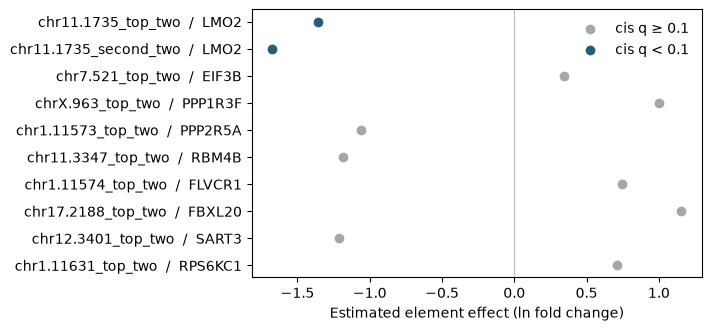

In [8]:
local = effects.loc[effects.q_cis.notna()].copy()
local["symbol"] = local.gene.map(rna.var.symbol.to_dict())
top = local.sort_values(["q_cis", "p_value", "element", "gene"]).head(10).iloc[::-1]
print(f"{local.q_cis.lt(0.1).sum()} cis discoveries among {len(local)} finite tests")

fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
ax.axvline(0, color="0.75", lw=0.8)
for passed, color in [(False, "0.65"), (True, "#285b77")]:
    mask = top.q_cis.lt(0.1).eq(passed)
    ax.scatter(top.posterior_mean[mask], np.flatnonzero(mask), color=color,
               label="cis q < 0.1" if passed else "cis q ≥ 0.1")
ax.set(yticks=range(len(top)), yticklabels=top.element.astype(str) + "  /  " + top.symbol.astype(str),
       xlabel="Estimated element effect (ln fold change)")
ax.legend(frameon=False)
plt.show()

In this subset, two of the 387 candidate pairs pass the cis threshold. For the remaining pairs, the screen could have missed a real effect. In the [cis power tutorial](gasperini_power.ipynb), you’ll reuse this same fitted file to ask how often an effect of a specified size would be detected at different cell counts. The [full-screen command](https://github.com/pinellolab/PerTurbo/blob/542a832346622cf3f50bba4c1327e969fc3b8229/examples/manuscript/README.md) gives the settings for the manuscript analysis.